<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS02_Praktikum01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('Titanic-Dataset.csv')

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [22]:
df.head(100)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,0,3,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
97,98,1,1,"Greenfield, Mr. William Bertram",male,23.0,0,1,PC 17759,63.3583,D10 D12,C
98,99,1,2,"Doling, Mrs. John T (Ada Julia Bone)",female,34.0,0,1,231919,23.0000,NaN,S


In [23]:
df.shape

(891, 12)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [25]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [26]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


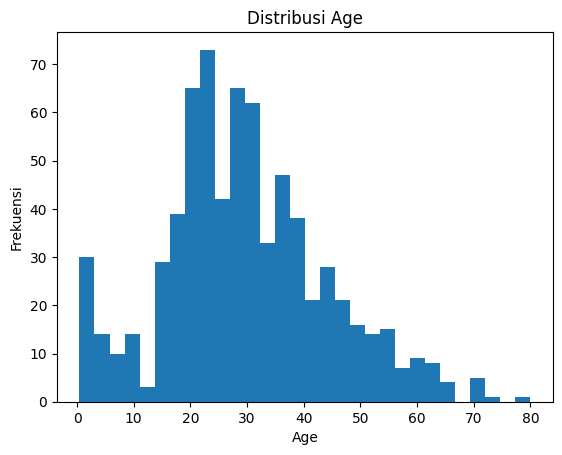

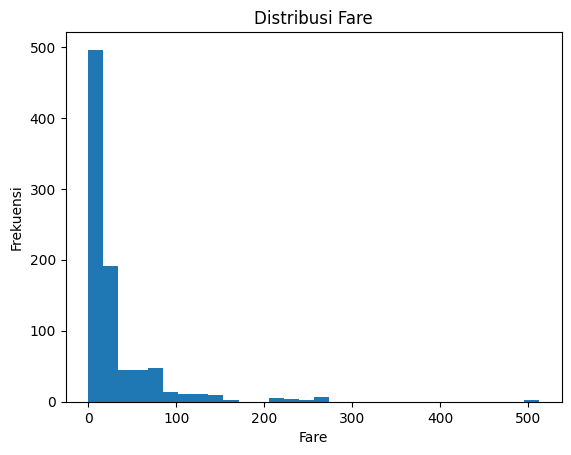

In [27]:
num_cols = ['Age','Fare']
for col in num_cols:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col); plt.ylabel('Frekuensi')
    plt.show()

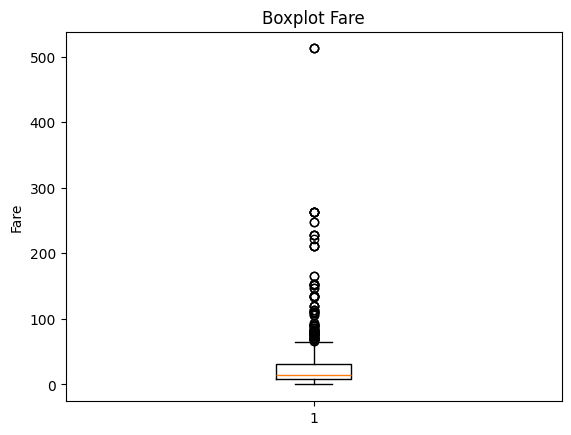

In [28]:
plt.figure()
plt.boxplot(df['Fare'].dropna(), vert=True)
plt.title('Boxplot Fare')
plt.ylabel('Fare')
plt.show()

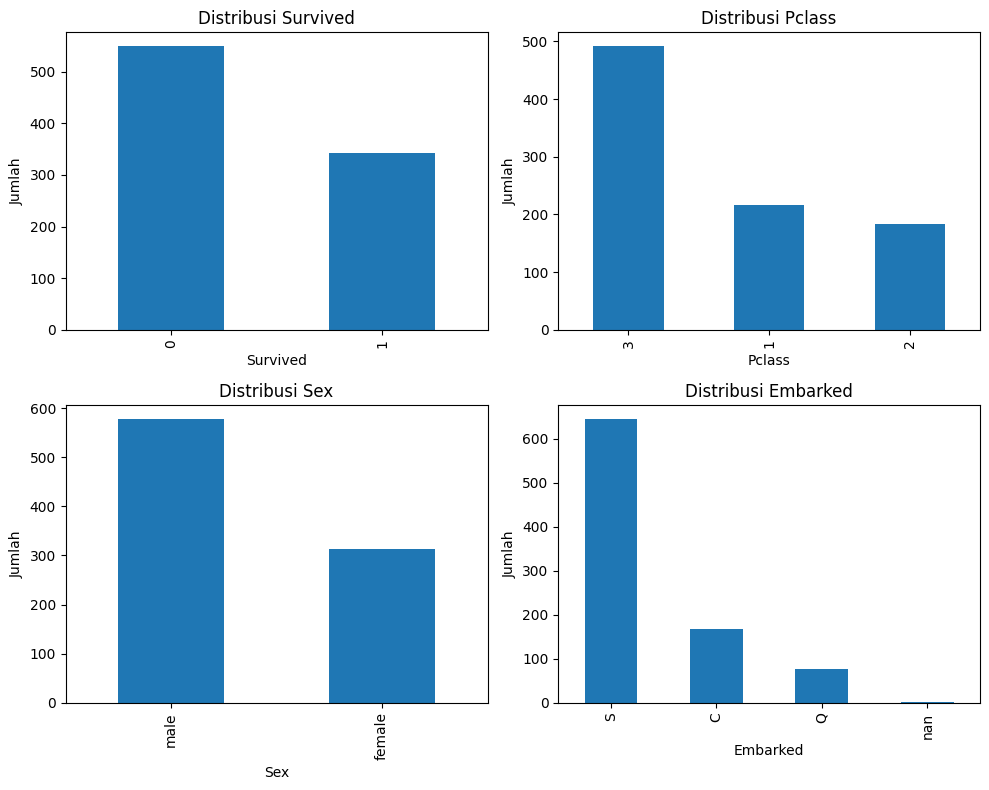

In [29]:
cat_cols = ['Survived','Pclass','Sex','Embarked']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    df[col].value_counts(dropna=False).plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

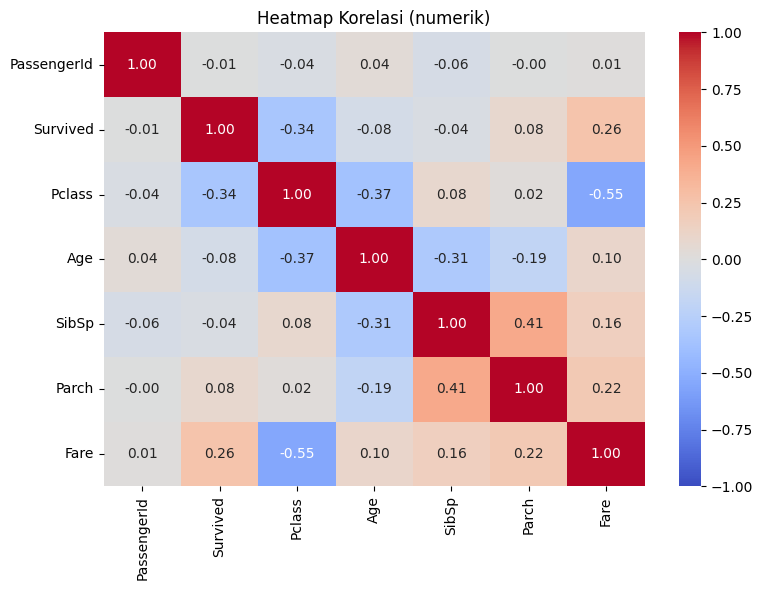

In [30]:
import seaborn as sns # Import seaborn for enhanced visualization

num_only = df.select_dtypes(include=[np.number])
corr = num_only.corr(numeric_only=True)

plt.figure(figsize=(8, 6)) # Increased figure size for better readability
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt=".2f") # Use seaborn.heatmap with annotation
plt.title('Heatmap Korelasi (numerik)')
plt.tight_layout()
plt.show()

In [31]:
corr['Survived'].sort_values(ascending=False)

,Survived
Survived,1.000000
Fare,0.257307
Parch,0.081629
PassengerId,-0.005007
SibSp,-0.035322
Age,-0.077221
Pclass,-0.338481


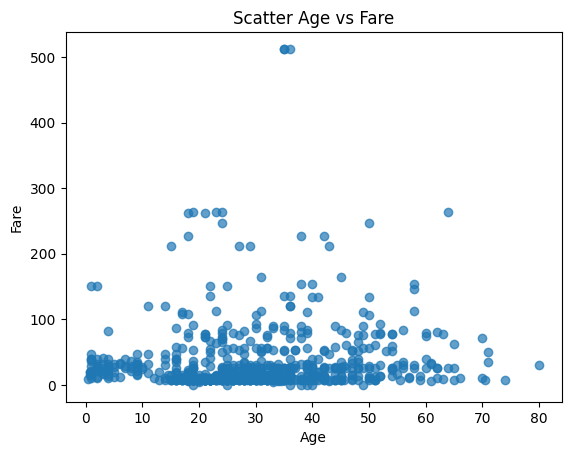

In [32]:
plt.figure()
surv_map = {0:'No', 1:'Yes'}
plt.scatter(df['Age'], df['Fare'], alpha=0.7)
plt.xlabel('Age'); plt.ylabel('Fare')
plt.title('Scatter Age vs Fare')
plt.show()

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('properti_multi_kota.csv')

df.head()

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [34]:
df.head(100)

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08
...,...,...,...,...,...,...,...,...
95,uas-properti/Jabodetabek,Tangerang,74.6,NaN,1.0,1.0,35.0,4.379893e+08
96,uas-properti/Jabodetabek,Bogor,30.0,NaN,1.0,1.0,19.0,2.000000e+08
97,uas-properti/Jabodetabek,Bekasi,97.2,NaN,4.0,3.0,21.0,8.883554e+08
98,uas-properti/Jabodetabek,Jakarta Selatan,85.0,NaN,2.0,1.0,16.0,1.464486e+09


In [35]:
df.shape

(64650, 8)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64650 entries, 0 to 64649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              64650 non-null  object 
 1   lokasi              64650 non-null  object 
 2   luas_m2             64650 non-null  float64
 3   luas_bangunan       63046 non-null  float64
 4   jumlah_kamar        64254 non-null  float64
 5   jumlah_kamar_mandi  64242 non-null  float64
 6   usia_bangunan       4789 non-null   float64
 7   harga               64650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 3.9+ MB


In [37]:
df.isnull().sum()

,0
sumber,0
lokasi,0
luas_m2,0
luas_bangunan,1604
jumlah_kamar,396
jumlah_kamar_mandi,408
usia_bangunan,59861
harga,0


In [38]:
df.describe()

,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
count,6.465000e+04,6.304600e+04,6.425400e+04,6.424200e+04,4789.000000,6.465000e+04
mean,1.400532e+03,1.591196e+05,6.305891e+03,1.454074e+04,1310.069117,1.019571e+14
std,2.754271e+05,3.933645e+07,1.597736e+06,3.684999e+06,950.008779,9.695374e+15
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,1.000000e+00
25%,7.200000e+01,4.000000e+01,2.000000e+00,1.000000e+00,27.000000,3.770000e+08
50%,9.800000e+01,6.300000e+01,2.000000e+00,2.000000e+00,2010.000000,7.391908e+08
75%,1.500000e+02,1.250000e+02,3.000000e+00,2.000000e+00,2021.000000,1.645000e+09
max,7.000000e+07,9.876543e+09,4.050000e+08,9.340000e+08,2026.000000,1.111111e+18


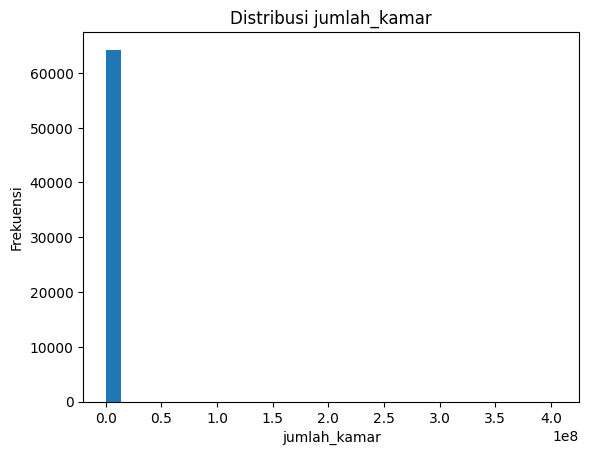

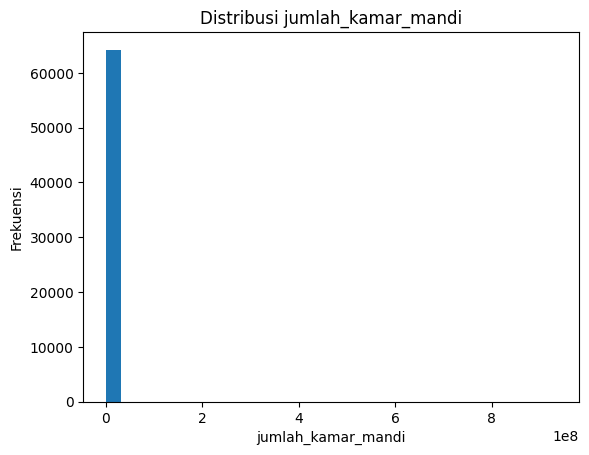

In [39]:
num_cols = ['jumlah_kamar','jumlah_kamar_mandi']
for col in num_cols:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col); plt.ylabel('Frekuensi')
    plt.show()

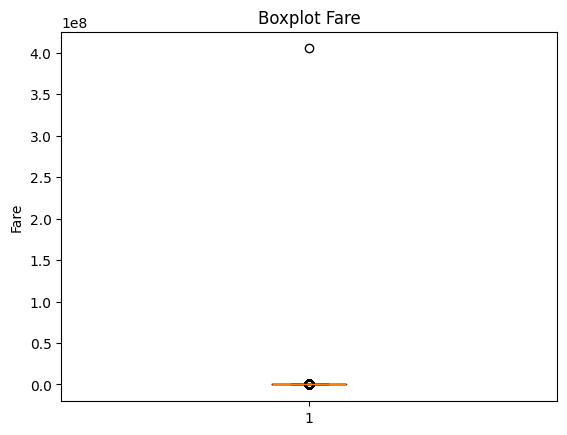

In [41]:
plt.figure()
plt.boxplot(df['jumlah_kamar'].dropna(), vert=True)
plt.title('Boxplot Fare')
plt.ylabel('Fare')
plt.show()

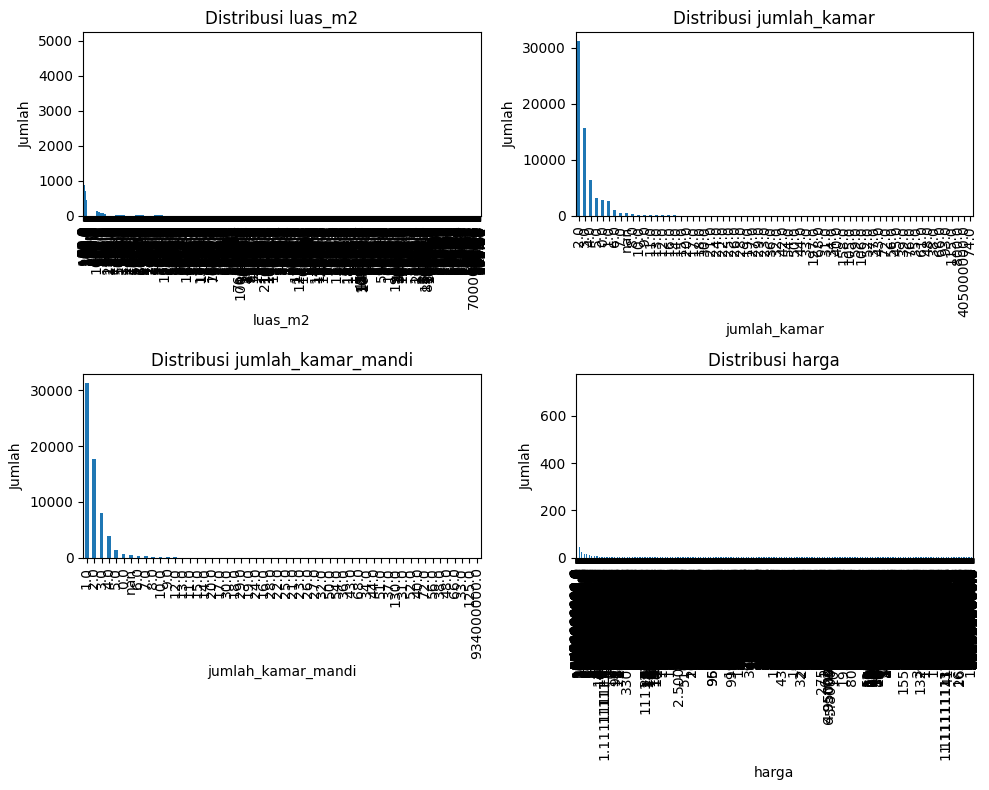

In [43]:
cat_cols = ['luas_m2','jumlah_kamar','jumlah_kamar_mandi','harga']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    df[col].value_counts(dropna=False).plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

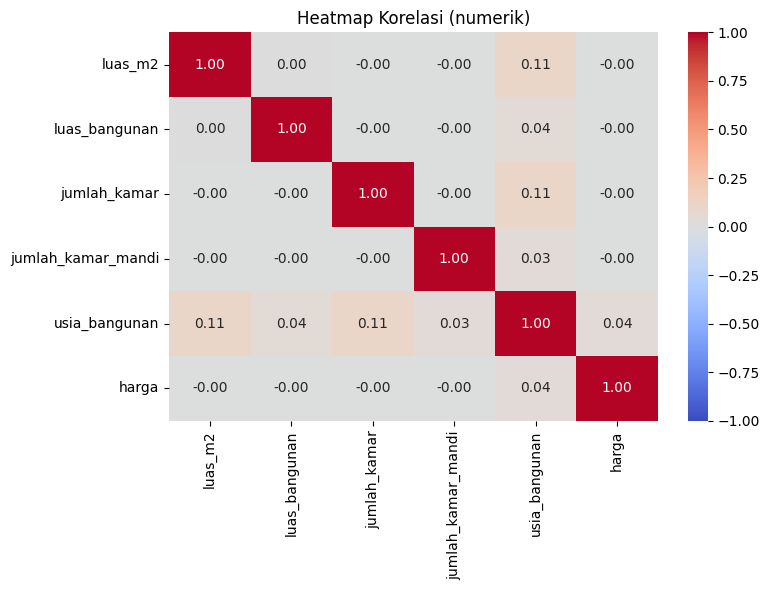

In [44]:
import seaborn as sns # Import seaborn for enhanced visualization

num_only = df.select_dtypes(include=[np.number])
corr = num_only.corr(numeric_only=True)

plt.figure(figsize=(8, 6)) # Increased figure size for better readability
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt=".2f") # Use seaborn.heatmap with annotation
plt.title('Heatmap Korelasi (numerik)')
plt.tight_layout()
plt.show()

In [45]:
corr['luas_m2'].sort_values(ascending=False)

,luas_m2
luas_m2,1.000000
usia_bangunan,0.108427
luas_bangunan,0.000130
jumlah_kamar_mandi,-0.000019
jumlah_kamar,-0.000019
harga,-0.000050


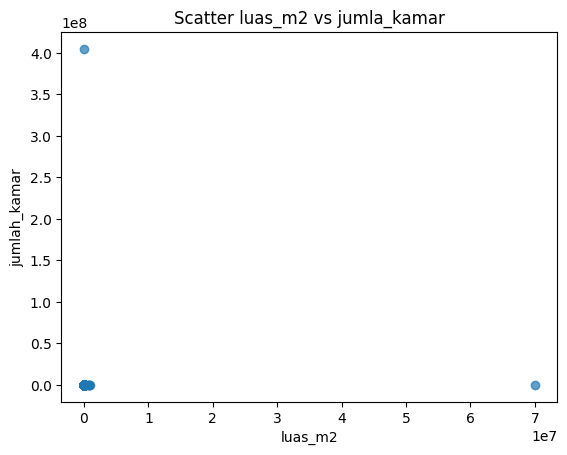

In [48]:
plt.figure()
surv_map = {0:'No', 1:'Yes'}
plt.scatter(df['luas_m2'], df['jumlah_kamar'], alpha=0.7)
plt.xlabel('luas_m2'); plt.ylabel('jumlah_kamar')
plt.title('Scatter luas_m2 vs jumla_kamar')
plt.show()